# Redes Neuronales 2026

---

# Guía de ejercicios N°9: *Perceptron simple* y *Perceptron* con una capa oculta
# Una neurona con dos entradas y `bias` estándar de PyTorch
## Implementación con PyTorch y `nn.Sequential`

En esta notebook utilizaremos una neurona con dos entradas:

$$
\mathbf{x}=(x_1,x_2),
$$

y el `bias` estándar de `nn.Linear`:

$$
h=w_1x_1+w_2x_2+b.
$$

Luego aplicaremos una función *sigmoide*:

$$
\hat y=\sigma(h)=\frac{1}{1+e^{-h}}.
$$

La primera parte contiene un **ejemplo completo resuelto para la compuerta OR**.

A partir de ese ejemplo, deberá repetir el procedimiento para:

1. intentar representar XOR con el mismo perceptrón simple;
2. analizar el resultado;
3. implementar una red con una capa oculta para representar XOR.

> La idea central de la actividad es distinguir entre **optimización** —cómo se ajustan los parámetros— y **capacidad de representación** —qué funciones puede representar una arquitectura.


## Objetivos

Al finalizar la actividad debería poder:

- construir un modelo sencillo con `nn.Sequential`;
- interpretar `nn.Linear(2,1)` y su `bias`;
- realizar un *forward pass*;
- calcular una función de costo;
- usar `loss.backward()` para obtener gradientes;
- actualizar parámetros mediante descenso por gradiente;
- entrenar con `torch.optim.SGD`;
- evaluar las cuatro configuraciones binarias;
- relacionar la frontera de decisión con $h=0$;
- comparar OR y XOR;
- implementar una red $2\to2\to1$ (red con una capa oculta).


# 1. Preparación del entorno


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)
torch.set_printoptions(precision=4, sci_mode=False)


Versión de PyTorch: 2.14.1+cpu


# 2. Datos de entrada

Para dos variables binarias existen solamente cuatro configuraciones:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$



In [ ]:
X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y_or = torch.tensor([
    [0.],
    [1.],
    [1.],
    [1.]
])

print("X =")
print(X)

print("y_or =")
print(y_or)

print("\nX.shape =", X.shape)
print("y_or.shape =", y_or.shape)


X =
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])
y_or =
tensor([[0.],
        [1.],
        [1.],
        [1.]])

X.shape = torch.Size([4, 2])
y_or.shape = torch.Size([4, 1])


## Interpretación de las dimensiones

`X.shape == (4,2)` significa:

- 4 ejemplos;
- 2 variables de entrada por ejemplo.

`y_or.shape == (4,1)` significa que existe una salida deseada por ejemplo.


# 3. Funciones auxiliares

Las siguientes funciones se utilizarán primero en el ejemplo OR y luego podrán reutilizarse en las actividades de XOR.


In [ ]:
def graficar_puntos(X, y, titulo):
    Xn = X.detach().cpu().numpy()
    yn = y.detach().cpu().numpy().ravel()

    plt.figure(figsize=(5.5, 5))

    for clase, marcador in [(0, "o"), (1, "s")]:
        mask = yn == clase
        plt.scatter(
            Xn[mask, 0],
            Xn[mask, 1],
            s=150,
            marker=marcador,
            edgecolors="black",
            label=f"Clase {clase}"
        )

    plt.xlim(-0.3, 1.3)
    plt.ylim(-0.3, 1.3)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


def crear_modelo_lineal(semilla=7):
    torch.manual_seed(semilla)

    return nn.Sequential(
        nn.Linear(2, 1),
        nn.Sigmoid()
    )

"""
def clases(modelo, X, umbral=0.5):
    with torch.no_grad():
        return (modelo(X) >= umbral).int()
"""

def entrenar(modelo, X, y, epocas=4000, eta=0.5):
    criterio = nn.MSELoss()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=eta)

    historial = {
        "antes": [],
        "despues": []
    }

    for _ in range(epocas):
        # 1. Forward pass
        y_pred = modelo(X)

        # 2. Costo antes de actualizar
        loss_antes = 0.5 * criterio(y_pred, y)
        historial["antes"].append(loss_antes.item())

        # 3. Gradientes
        optimizador.zero_grad()
        loss_antes.backward()

        # 4. Actualización de parámetros
        optimizador.step()

        # 5. Costo después de actualizar
        with torch.no_grad():
            y_pred_despues = modelo(X)
            loss_despues = 0.5 * criterio(y_pred_despues, y)

        historial["despues"].append(loss_despues.item())

    return historial


def graficar_costos_antes_despues(historial, titulo):
    epocas = range(1, len(historial["antes"]) + 1)

    plt.figure(figsize=(7.5, 4.5))
    plt.plot(epocas, historial["antes"], label="Antes de actualizar")
    plt.plot(epocas, historial["despues"], "--", label="Después de actualizar")
    plt.xlabel("Época")
    plt.ylabel("Costo")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


def graficar_frontera_lineal(modelo, X, y, titulo):
    Xn = X.detach().cpu().numpy()
    yn = y.detach().cpu().numpy().ravel()

    w = modelo[0].weight.detach().flatten()
    b = modelo[0].bias.detach().item()

    plt.figure(figsize=(5.5, 5))

    for clase, marcador in [(0, "o"), (1, "s")]:
        mask = yn == clase
        plt.scatter(
            Xn[mask, 0],
            Xn[mask, 1],
            s=150,
            marker=marcador,
            edgecolors="black",
            label=f"Clase {clase}"
        )

    # Frontera: w1*x1 + w2*x2 + b = 0
    if abs(w[1].item()) > 1e-10:
        x1 = torch.linspace(-0.3, 1.3, 200)
        x2 = -(w[0] * x1 + b) / w[1]
        plt.plot(x1.numpy(), x2.numpy(), label="Frontera h=0")
    elif abs(w[0].item()) > 1e-10:
        x1_const = -b / w[0].item()
        plt.axvline(x1_const, label="Frontera h=0")

    plt.xlim(-0.3, 1.3)
    plt.ylim(-0.3, 1.3)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()


# 4. Ejemplo resuelto: compuerta OR

La tabla OR es:

| $x_1$ | $x_2$ | OR |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

Primero observaremos la geometría del problema.


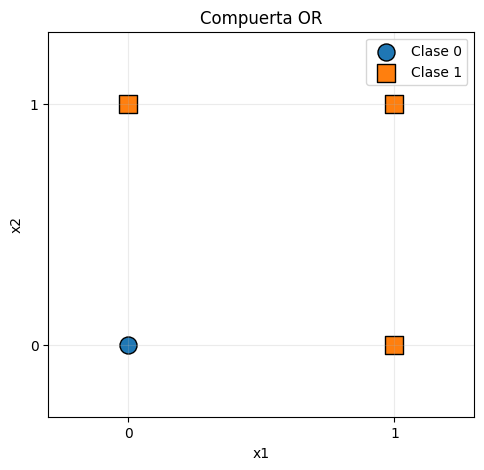

In [ ]:
graficar_puntos(X, y_or, "Compuerta OR")


## 4.1. Construcción del *perceptron* simple

La arquitectura es:

```python
nn.Sequential(
    nn.Linear(2, 1),
    nn.Sigmoid()
)
```
```text
x1 ─────┐
        ├──> Linear(2,1, bias=True) ──> Sigmoid ──> ŷ
x2 ─────┘
```


`nn.Linear(2,1)` calcula:

$$
h=w_1x_1+w_2x_2+b.
$$

La sigmoide produce:

$$
\hat y=\sigma(h).
$$


In [ ]:
modelo_or = crear_modelo_lineal(semilla=7)
print(modelo_or)


Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)


## 4.2. Inspección de parámetros

`weight` contiene $w_1$ y $w_2$.

`bias` contiene $b$.


In [ ]:
capa_lineal = modelo_or[0]

print("Pesos [w1, w2]:")
print(capa_lineal.weight)
print("Shape de weight:", capa_lineal.weight.shape)

print("\nBias b:")
print(capa_lineal.bias)
print("Shape de bias:", capa_lineal.bias.shape)


Pesos [w1, w2]:
Parameter containing:
tensor([[ 0.0494, -0.4260]], requires_grad=True)
Shape de weight: torch.Size([1, 2])

Bias b:
Parameter containing:
tensor([0.2252], requires_grad=True)
Shape de bias: torch.Size([1])


## 4.3. *Forward pass* inicial


In [ ]:
with torch.no_grad():
    y_inicial_or = modelo_or(X)
    clases_iniciales_or = (y_inicial_or >= 0.5).int()

print("Salidas iniciales:")
print(y_inicial_or)

print("\nClases iniciales:")
print(clases_iniciales_or)


Salidas iniciales:
tensor([[0.5561],
        [0.4500],
        [0.5682],
        [0.4622]])

Clases iniciales:
tensor([[1],
        [0],
        [1],
        [0]], dtype=torch.int32)


## 4.4. Función de costo

Usaremos:

$$
E=
\frac{1}{2M}
\sum_{m=1}^{M}
\left(\hat y^{(m)}-y^{(m)}\right)^2.
$$

`nn.MSELoss()` calcula el promedio del error cuadrático. Multiplicamos por $0.5$ para mantener la misma convención utilizada en la derivaciones matemáticas usuales.


In [ ]:
criterio = nn.MSELoss()

y_pred = modelo_or(X)
loss_or = 0.5 * criterio(y_pred, y_or)

print("Costo inicial para OR:", loss_or.item())


Costo inicial para OR: 0.13592258095741272


## 4.5. Cálculo de gradientes

`loss.backward()` calcula los gradientes respecto de todos los parámetros aprendibles.

Los gradientes de $w_1,w_2$ quedan en:

```python
modelo_or[0].weight.grad
```

y el gradiente de $b$ en:

```python
modelo_or[0].bias.grad
```


In [ ]:
modelo_or.zero_grad()

y_pred = modelo_or(X)
loss_or = 0.5 * criterio(y_pred, y_or)
loss_or.backward()

print("Gradientes de los pesos:")
print(modelo_or[0].weight.grad)

print("\nGradiente del bias:")
print(modelo_or[0].bias.grad)


Gradientes de los pesos:
tensor([[-0.0599, -0.0675]])

Gradiente del bias:
tensor([-0.0596])


## 4.6. Una actualización manual

El descenso por gradiente utiliza:

$$
\theta_i
\leftarrow
\theta_i-
\eta\frac{\partial E}{\partial\theta_i}.
$$

Para modificar parámetros directamente utilizamos `torch.no_grad()`.


In [ ]:
eta = 0.5

modelo_manual = crear_modelo_lineal(semilla=7)
criterio_manual = nn.MSELoss()

# Forward y backward
y_pred = modelo_manual(X)
loss_antes_manual = 0.5 * criterio_manual(y_pred, y_or)

modelo_manual.zero_grad()
loss_antes_manual.backward()

print("Costo antes:", loss_antes_manual.item())

with torch.no_grad():
    for parametro in modelo_manual.parameters():
        parametro -= eta * parametro.grad

with torch.no_grad():
    loss_despues_manual = 0.5 * criterio_manual(modelo_manual(X), y_or)

print("Costo después:", loss_despues_manual.item())


Costo antes: 0.13592258095741272
Costo después: 0.1301986575126648


## 4.7. Entrenamiento con SGD

En cada época:

1. hacemos el *forward pass*;
2. calculamos $E_{\mathrm{antes}}$;
3. calculamos gradientes;
4. actualizamos parámetros;
5. calculamos $E_{\mathrm{después}}$.


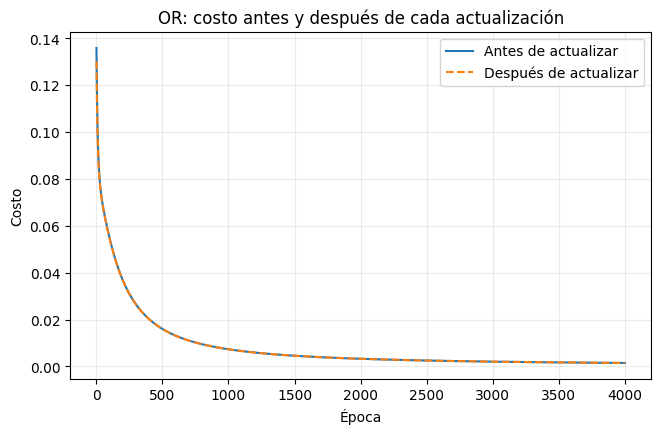

In [ ]:
modelo_or = crear_modelo_lineal(semilla=7)
historial_or = entrenar(modelo_or, X, y_or, epocas=4000, eta=0.5)

graficar_costos_antes_despues(
    historial_or,
    "OR: costo antes y después de cada actualización"
)


## 4.8. Evaluación del modelo OR


In [ ]:
with torch.no_grad():
    salidas_or = modelo_or(X)
    pred_or = (salidas_or >= 0.5).int()

aciertos_or = (pred_or == y_or.int()).sum().item()

print(" x1   x2   salida      predicción   correcta")
print("------------------------------------------------")

for i in range(len(X)):
    print(
        f" {int(X[i,0])}    {int(X[i,1])}    "
        f"{salidas_or[i].item():.4f}          "
        f"{pred_or[i].item()}            "
        f"{int(y_or[i].item())}"
    )

print(f"\nAciertos: {aciertos_or}/{len(X)}")
print("Costo final:", historial_or["despues"][-1])


 x1   x2   salida      predicción   correcta
------------------------------------------------
 0    0    0.0813          0            0
 0    1    0.9495          1            1
 1    0    0.9495          1            1
 1    1    0.9997          1            1

Aciertos: 4/4
Costo final: 0.0014637877466157079


## 4.9. Frontera de decisión

Como:

$$
\sigma(0)=0.5,
$$

la frontera de decisión se encuentra en:

$$
h=0.
$$

Por lo tanto:

$$
w_1x_1+w_2x_2+b=0.
$$


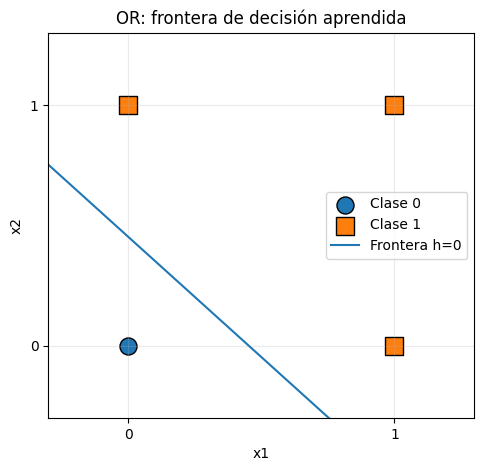

In [ ]:
graficar_frontera_lineal(
    modelo_or,
    X,
    y_or,
    "OR: frontera de decisión aprendida"
)


# 5. Actividad guiada: XOR con el mismo perceptrón simple

Ahora deberá repetir los pasos del ejemplo OR utilizando la compuerta XOR, **sin modificar todavía la arquitectura**.


## Lista de tareas — XOR con perceptrón simple

1. Defina la tabla de verdad de XOR.
2. Grafique los cuatro puntos.
3. Cree un nuevo perceptrón simple.
4. Inspeccione los parámetros iniciales.
5. Realice el forward pass inicial.
6. Obtenga las clases usando el umbral $0.5$.
7. Calcule el costo inicial.
8. Calcule e inspeccione los gradientes.
9. Realice una actualización manual.
10. Entrene un modelo nuevo con SGD.
11. Grafique el costo antes y después de cada actualización.
12. Evalúe las cuatro configuraciones.
13. Calcule el número de aciertos.
14. Inspeccione los parámetros finales.
15. Grafique la frontera de decisión.
16. Repita el entrenamiento con distintas semillas.
17. Compare la geometría de OR y XOR.
18. Formule una conclusión sobre la capacidad de la arquitectura.


## Tarea 1 — Definir las salidas de XOR

XOR vale 1 cuando las dos entradas son diferentes.

Construya `y_xor` con `shape == (4,1)`.


In [16]:
y_xor = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

print("y_xor =")
print(y_xor)
print("\ny_xor.shape =", y_xor.shape)


y_xor =
tensor([[0.],
        [1.],
        [1.],
        [0.]])

y_xor.shape = torch.Size([4, 1])


## Tarea 2 — Graficar XOR

Use la función `graficar_puntos(...)`.

Antes de entrenar, observe la disposición de las dos clases.


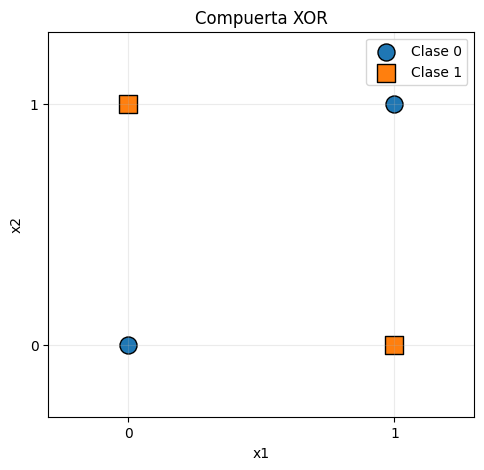

In [17]:
# TODO 2
graficar_puntos(X, y_xor, "Compuerta XOR")


## Tarea 3 — Crear un nuevo perceptrón simple

No reutilice el modelo entrenado para OR.

Use la misma arquitectura:

```python
nn.Linear(2, 1)
nn.Sigmoid()
```


In [18]:
modelo_xor = crear_modelo_lineal(semilla=7)
print(modelo_xor)


Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)


## Tarea 4 — Inspeccionar parámetros iniciales

Imprima los pesos, el `bias` y sus `shape`.

Identifique $w_1$, $w_2$ y $b$.


In [19]:
capa_lineal_xor = modelo_xor[0]

print("Pesos [w1, w2]:")
print(capa_lineal_xor.weight)
print("Shape de weight:", capa_lineal_xor.weight.shape)

print("\nBias b:")
print(capa_lineal_xor.bias)
print("Shape de bias:", capa_lineal_xor.bias.shape)

# Identificación explícita de cada parámetro
w1 = capa_lineal_xor.weight[0, 0].item()
w2 = capa_lineal_xor.weight[0, 1].item()
b = capa_lineal_xor.bias[0].item()

print(f"\nValores escalares -> w1 = {w1:.6f}, w2 = {w2:.6f}, b = {b:.6f}")

Pesos [w1, w2]:
Parameter containing:
tensor([[ 0.0494, -0.4260]], requires_grad=True)
Shape de weight: torch.Size([1, 2])

Bias b:
Parameter containing:
tensor([0.2252], requires_grad=True)
Shape de bias: torch.Size([1])

Valores escalares -> w1 = 0.049388, w2 = -0.425957, b = 0.225159


## Tarea 5 — *Forward pass* inicial

Obtenga:

- las salidas continuas;
- las clases usando el umbral $0.5$.

Compare con la tabla de verdad de XOR.


In [20]:
with torch.no_grad():
    y_inicial_xor = modelo_xor(X)
    clases_iniciales_xor = (y_inicial_xor >= 0.5).int()

print("Salidas continuas iniciales:")
print(y_inicial_xor)

print("\nClases iniciales (umbral 0.5):")
print(clases_iniciales_xor)

# Comparación directa con la tabla de verdad de XOR
print("\n x1   x2   salida_continua   clase_pred   real_XOR")
print("---------------------------------------------------")
for i in range(len(X)):
    print(
        f" {int(X[i,0])}    {int(X[i,1])}       "
        f"{y_inicial_xor[i].item():.4f}            "
        f"{clases_iniciales_xor[i].item()}            "
        f"{int(y_xor[i].item())}"
    )


Salidas continuas iniciales:
tensor([[0.5561],
        [0.4500],
        [0.5682],
        [0.4622]])

Clases iniciales (umbral 0.5):
tensor([[1],
        [0],
        [1],
        [0]], dtype=torch.int32)

 x1   x2   salida_continua   clase_pred   real_XOR
---------------------------------------------------
 0    0       0.5561            1            0
 0    1       0.4500            0            1
 1    0       0.5682            1            1
 1    1       0.4622            0            0


## Tarea 6 — Costo inicial

Use la misma expresión utilizada para OR:

$$
E=
\frac{1}{2M}
\sum_m
\left(\hat y^{(m)}-y^{(m)}\right)^2.
$$


In [21]:
criterio = nn.MSELoss()

y_pred = modelo_xor(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)

print("Costo inicial para XOR:", loss_xor.item())


Costo inicial para XOR: 0.12647753953933716


## Tarea 7 — Gradientes

Repita:

```python
modelo_xor.zero_grad()
...
loss_xor.backward()
```

e inspeccione:

```python
modelo_xor[0].weight.grad
modelo_xor[0].bias.grad
```


In [22]:
modelo_xor.zero_grad()

y_pred = modelo_xor(X)
loss_xor = 0.5 * criterio(y_pred, y_xor)
loss_xor.backward()

print("Gradientes de los pesos:")
print(modelo_xor[0].weight.grad)

print("\nGradiente del bias:")
print(modelo_xor[0].bias.grad)

Gradientes de los pesos:
tensor([[ 0.0022, -0.0053]])

Gradiente del bias:
tensor([0.0025])


## Tarea 8 — Actualización manual

Actualice los parámetros dentro de:

```python
with torch.no_grad():
```

y vuelva a calcular el costo.

**Pregunta:** ¿disminuyó el costo después del paso?


In [23]:
eta = 0.5

modelo_manual_xor = crear_modelo_lineal(semilla=7)
criterio_manual = nn.MSELoss()

# Forward y backward inicial
y_pred = modelo_manual_xor(X)
loss_antes_manual = 0.5 * criterio_manual(y_pred, y_xor)

modelo_manual_xor.zero_grad()
loss_antes_manual.backward()

print("Costo antes:", loss_antes_manual.item())

# Actualización manual de parámetros
with torch.no_grad():
    for parametro in modelo_manual_xor.parameters():
        parametro -= eta * parametro.grad

# Nuevo cálculo del costo
with torch.no_grad():
    loss_despues_manual = 0.5 * criterio_manual(modelo_manual_xor(X), y_xor)

print("Costo después:", loss_despues_manual.item())

Costo antes: 0.12647753953933716
Costo después: 0.1264578402042389


Sí, el costo disminuye levemente después de este primer paso (baja desde el valor inicial aleatorio hacia $\approx 0.125$), porque los parámetros se mueven en la dirección opuesta al gradiente ($\theta \leftarrow \theta - \eta \nabla_\theta E$). Sin embargo, esa pequeña mejora inicial solo lleva al modelo hacia una salida plana cercana a $0.5$ para los cuatro puntos, punto en el cual el descenso se estancará porque los gradientes de las dos diagonales de XOR se cancelan entre sí.

## Tarea 9 — Entrenamiento con SGD

Cree un modelo nuevo y use `entrenar(...)`.

Como punto de partida:

```python
epocas=500
eta=0.5
```

Luego puede experimentar con más épocas.


In [26]:
modelo_xor = crear_modelo_lineal(semilla=7)
historial_xor = entrenar(modelo_xor, X, y_xor, epocas=500, eta=0.5)

print("Costo inicial:", historial_xor["antes"][0])
print("Costo final:", historial_xor["despues"][-1])

Costo inicial: 0.12647753953933716
Costo final: 0.1250050663948059


## Tarea 10 — Graficar el costo

Analice:

- ¿disminuye al principio?
- ¿se estabiliza?
- ¿la diferencia entre $E_{\mathrm{antes}}$ y $E_{\mathrm{después}}$ se hace pequeña?


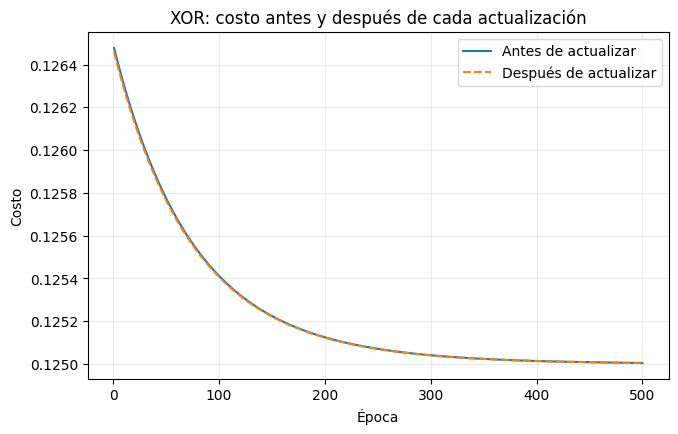

In [27]:
graficar_costos_antes_despues(
    historial_xor,
    "XOR: costo antes y después de cada actualización"
)


**Disminución inicial:** Al comienzo del entrenamiento (época 0), el costo parte desde aproximadamente 0.1265 y desciende suavemente durante las primeras 300 épocas.   

**Estabilización (estancamiento):** A partir de la época 350–400, la curva se aplana por completo y converge asintóticamente a 0.1250. Esto demuestra que el perceptrón simple alcanzó su límite matemático para este problema (prediciendo $\hat{y} \approx 0.5$ para las cuatro entradas) y no puede reducir más el error.   

**Diferencia entre $E_{\text{antes}}$ y $E_{\text{después}}$: L**a línea azul continua (Antes de actualizar) y la línea naranja discontinua (Después de actualizar) aparecen prácticamente superpuestas desde el inicio hasta el final. Esto evidencia que los pasos de actualización son diminutos porque los gradientes de las diagonales opuestas de XOR se cancelan entre sí, haciendo que cada actualización apenas modifique los parámetros.   

## Tarea 11 — Evaluación de las cuatro entradas

Muestre para cada ejemplo:

```text
x1   x2   salida   predicción   valor correcto
```

Calcule también la cantidad de aciertos.

No observe solamente las clases: examine los valores continuos $\hat y$.


In [28]:
with torch.no_grad():
    salidas_xor = modelo_xor(X)
    pred_xor = (salidas_xor >= 0.5).int()

aciertos_xor = (pred_xor == y_xor.int()).sum().item()

print(" x1   x2   salida      predicción   valor correcto")
print("----------------------------------------------------")

for i in range(len(X)):
    print(
        f" {int(X[i,0])}    {int(X[i,1])}    "
        f"{salidas_xor[i].item():.4f}          "
        f"{pred_xor[i].item()}               "
        f"{int(y_xor[i].item())}"
    )

print(f"\nAciertos: {aciertos_xor}/{len(X)}")

 x1   x2   salida      predicción   valor correcto
----------------------------------------------------
 0    0    0.5050          1               0
 0    1    0.4997          0               1
 1    0    0.5019          1               1
 1    1    0.4966          0               0

Aciertos: 2/4


## Tarea 12 — Parámetros finales y frontera

Imprima:

$$
w_1,\quad w_2,\quad b.
$$

Luego grafique la frontera:

$$
w_1x_1+w_2x_2+b=0.
$$

**Pregunta:** ¿una única recta puede separar correctamente las dos clases de XOR?


Parámetros finales -> w1 = -0.012329, w2 = -0.021356, b = 0.020046


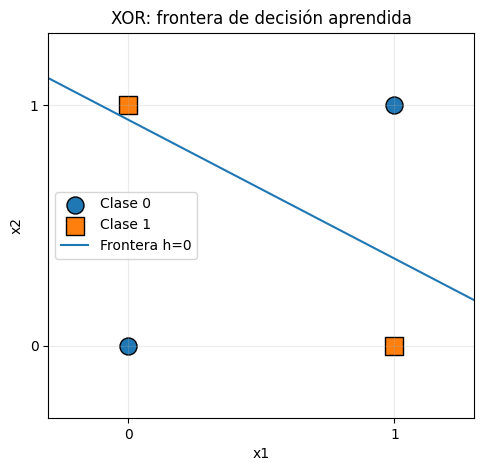

In [29]:
# Extraer e imprimir parámetros finales
w1_final = modelo_xor[0].weight[0, 0].item()
w2_final = modelo_xor[0].weight[0, 1].item()
b_final = modelo_xor[0].bias[0].item()

print(f"Parámetros finales -> w1 = {w1_final:.6f}, w2 = {w2_final:.6f}, b = {b_final:.6f}")

# Graficar la frontera de decisión aprendida
graficar_frontera_lineal(
    modelo_xor,
    X,
    y_xor,
    "XOR: frontera de decisión aprendida"
)

No, una única recta no puede separar correctamente las dos clases de XOR. Al tener las clases ubicadas en diagonales opuestas ((0,0) y (1,1) frente a (0,1) y (1,0)), cualquier línea recta que trace el perceptrón simple dejará inevitablemente puntos de ambas clases mezclados o caerá sobre uno de los pares, logrando como máximo 2 de 4 aciertos. Por eso los pesos $w_1$, $w_2$ y el sesgo $b$ tienden todos hacia cero.

## Tarea 13 — Distintas inicializaciones

Repita el entrenamiento con varias semillas, por ejemplo:

```python
[1, 7, 15, 25]
```

Para cada caso registre:

- costo final;
- salidas continuas;
- predicciones;
- número de aciertos.

**Pregunta:** ¿cambiar la inicialización modifica la capacidad de representación del modelo?


In [30]:
semillas = [1, 7, 15, 25]

for s in semillas:
    modelo_temp = crear_modelo_lineal(semilla=s)
    hist_temp = entrenar(modelo_temp, X, y_xor, epocas=4000, eta=0.5)

    with torch.no_grad():
        salidas_temp = modelo_temp(X)
        pred_temp = (salidas_temp >= 0.5).int()
        aciertos_temp = (pred_temp == y_xor.int()).sum().item()

    costo_final = hist_temp["despues"][-1]
    salidas_lista = [round(val.item(), 4) for val in salidas_temp]
    pred_lista = [val.item() for val in pred_temp]

    print(f"=== Semilla {s} ===")
    print(f"Costo final:        {costo_final:.6f}")
    print(f"Salidas continuas:  {salidas_lista}")
    print(f"Predicciones:       {pred_lista}")
    print(f"Número de aciertos: {aciertos_temp}/{len(X)}\n")

=== Semilla 1 ===
Costo final:        0.125000
Salidas continuas:  [0.5, 0.5, 0.5, 0.5]
Predicciones:       [1, 1, 1, 1]
Número de aciertos: 2/4

=== Semilla 7 ===
Costo final:        0.125000
Salidas continuas:  [0.5, 0.5, 0.5, 0.5]
Predicciones:       [1, 1, 1, 1]
Número de aciertos: 2/4

=== Semilla 15 ===
Costo final:        0.125000
Salidas continuas:  [0.5, 0.5, 0.5, 0.5]
Predicciones:       [1, 1, 1, 1]
Número de aciertos: 2/4

=== Semilla 25 ===
Costo final:        0.125000
Salidas continuas:  [0.5, 0.5, 0.5, 0.5]
Predicciones:       [1, 1, 1, 1]
Número de aciertos: 2/4



Esto demuestra experimentalmente que el estancamiento no es un problema de mala inicialización ni de óptimos locales, sino una limitación estructural del perceptrón simple frente a datos no linealmente separables.

# 6. Análisis de la separabilidad lineal de XOR

Use la condición:

$$
h=w_1x_1+w_2x_2+b.
$$

Para clase 1:

$$
h\geq0.
$$

Para clase 0:

$$
h<0.
$$

Escriba una condición para cada punto:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$

Luego responda:

1. ¿pueden satisfacerse simultáneamente las cuatro condiciones?
2. ¿el problema observado se debe a que SGD "no funciona"?
3. ¿aumentar el número de épocas cambia la familia de funciones que puede representar una sola neurona?


# Parte 2:
# *Perceptron* con una capa oculta

# 7. Actividad guiada: XOR con una capa oculta

Ahora **aumentaremos la capacidad del modelo**.

Utilizaremos una red:

$$
2\to2\to1.
$$

En PyTorch:

```python
nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)
```

La primera sigmoide actúa **elemento a elemento** sobre las dos neuronas ocultas.

El esquema de entrenamiento seguirá siendo el mismo que en OR:

$$
\text{forward}
\rightarrow
\text{costo}
\rightarrow
\text{backward}
\rightarrow
\text{actualización}.
$$


## Lista de tareas — XOR con perceptrón multicapa

1. Construya la red $2\to2\to1$.
2. Imprima el modelo e identifique sus componentes.
3. Inspeccione `weight` y `bias` de las dos capas lineales.
4. Cuente los parámetros aprendibles.
5. Realice un forward pass inicial.
6. Calcule el costo inicial.
7. Calcule los gradientes de ambas capas.
8. Entrene la red con la misma función `entrenar(...)`.
9. Grafique el costo.
10. Evalúe las cuatro entradas XOR.
11. Calcule el número de aciertos.
12. Compare las salidas con las del perceptrón simple.
13. Grafique la región de decisión.
14. Compare la frontera multicapa con la frontera lineal.
15. Formule una conclusión sobre el efecto de la capa oculta.


## Tarea 14 — Construir la red multicapa

Cree `modelo_mlp`.

Puede usar una semilla para reproducibilidad.


In [31]:
torch.manual_seed(7)

modelo_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)

print(modelo_mlp)

Sequential(
  (0): Linear(in_features=2, out_features=2, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=2, out_features=1, bias=True)
  (3): Sigmoid()
)


## Tarea 15 — Inspeccionar parámetros

Las capas lineales son:

```python
modelo_mlp[0]
modelo_mlp[2]
```

Para ambas inspeccione:

- `weight`;
- `weight.shape`;
- `bias`;
- `bias.shape`.

Luego cuente todos los parámetros aprendibles.

Puede usar:

```python
sum(p.numel() for p in modelo_mlp.parameters())
```


In [32]:
# Inspección de la capa oculta: modelo_mlp[0] (Linear 2 -> 2)
print("=== Capa oculta: modelo_mlp[0] ===")
print("weight:\n", modelo_mlp[0].weight)
print("weight.shape:", modelo_mlp[0].weight.shape)
print("bias:\n", modelo_mlp[0].bias)
print("bias.shape:", modelo_mlp[0].bias.shape)

# Inspección de la capa de salida: modelo_mlp[2] (Linear 2 -> 1)
print("\n=== Capa de salida: modelo_mlp[2] ===")
print("weight:\n", modelo_mlp[2].weight)
print("weight.shape:", modelo_mlp[2].weight.shape)
print("bias:\n", modelo_mlp[2].bias)
print("bias.shape:", modelo_mlp[2].bias.shape)

# Conteo total de parámetros aprendibles
total_parametros = sum(p.numel() for p in modelo_mlp.parameters())
print("\nTotal de parámetros aprendibles:", total_parametros)

=== Capa oculta: modelo_mlp[0] ===
weight:
 Parameter containing:
tensor([[ 0.0494, -0.4260],
        [ 0.2252,  0.2219]], requires_grad=True)
weight.shape: torch.Size([2, 2])
bias:
 Parameter containing:
tensor([-0.3779, -0.1060], requires_grad=True)
bias.shape: torch.Size([2])

=== Capa de salida: modelo_mlp[2] ===
weight:
 Parameter containing:
tensor([[-0.4142,  0.1835]], requires_grad=True)
weight.shape: torch.Size([1, 2])
bias:
 Parameter containing:
tensor([-0.1905], requires_grad=True)
bias.shape: torch.Size([1])

Total de parámetros aprendibles: 9


## Tarea 16 — Forward pass inicial y costo

Evalúe la red multicapa sobre las cuatro entradas XOR.

Obtenga:

- salidas continuas;
- clases con umbral $0.5$;
- costo inicial.


In [33]:
criterio_mlp = nn.MSELoss()

with torch.no_grad():
    salidas_iniciales_mlp = modelo_mlp(X)
    pred_iniciales_mlp = (salidas_iniciales_mlp >= 0.5).int()
    loss_inicial_mlp = 0.5 * criterio_mlp(salidas_iniciales_mlp, y_xor)

print("Salidas continuas iniciales:")
print(salidas_iniciales_mlp)

print("\nClases predichas (umbral 0.5):")
print(pred_iniciales_mlp)

print(f"\nCosto inicial: {loss_inicial_mlp.item():.6f}")

Salidas continuas iniciales:
tensor([[0.4324],
        [0.4448],
        [0.4337],
        [0.4463]])

Clases predichas (umbral 0.5):
tensor([[0],
        [0],
        [0],
        [0]], dtype=torch.int32)

Costo inicial: 0.126875


## Tarea 17 — Gradientes de ambas capas

Después de `loss.backward()`, inspeccione:

```python
modelo_mlp[0].weight.grad
modelo_mlp[0].bias.grad
modelo_mlp[2].weight.grad
modelo_mlp[2].bias.grad
```

Observe que autograd calcula gradientes para todos los parámetros que participaron en el forward pass.


In [34]:
criterio_mlp = nn.MSELoss()

# Forward pass con seguimiento de gradientes
salidas_mlp = modelo_mlp(X)
loss_mlp = 0.5 * criterio_mlp(salidas_mlp, y_xor)

# Limpiar gradientes previos y ejecutar retropropagación
modelo_mlp.zero_grad()
loss_mlp.backward()

# Inspección de gradientes de la capa oculta (índice 0)
print("=== Gradientes capa oculta: modelo_mlp[0] ===")
print("weight.grad:\n", modelo_mlp[0].weight.grad)
print("bias.grad:\n", modelo_mlp[0].bias.grad)

# Inspección de gradientes de la capa de salida (índice 2)
print("\n=== Gradientes capa de salida: modelo_mlp[2] ===")
print("weight.grad:\n", modelo_mlp[2].weight.grad)
print("bias.grad:\n", modelo_mlp[2].bias.grad)

=== Gradientes capa oculta: modelo_mlp[0] ===
weight.grad:
 tensor([[ 0.0010,  0.0005],
        [-0.0004, -0.0003]])
bias.grad:
 tensor([ 0.0014, -0.0007])

=== Gradientes capa de salida: modelo_mlp[2] ===
weight.grad:
 tensor([[-0.0055, -0.0079]])
bias.grad:
 tensor([-0.0149])


## Tarea 18 — Entrenamiento

Puede reutilizar directamente `entrenar(...)`.

Como punto de partida pruebe:

```python
epocas=6000
eta=1.0
```

Si el resultado no es satisfactorio, experimente con la semilla, las épocas o la tasa de aprendizaje.


In [35]:
torch.manual_seed(7)

modelo_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.Sigmoid(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)

historial_mlp = entrenar(modelo_mlp, X, y_xor, epocas=6000, eta=1.0)

print("Costo inicial (época 1):", historial_mlp["antes"][0])
print("Costo final (época 6000):", historial_mlp["despues"][-1])

Costo inicial (época 1): 0.12687496840953827
Costo final (época 6000): 0.0012620978523045778


## Tarea 19 — Costo y evaluación

Grafique el historial y luego informe:

- las cuatro salidas continuas;
- las predicciones;
- los valores correctos;
- el número de aciertos;
- el costo final.

Compare estos resultados con el perceptrón simple.


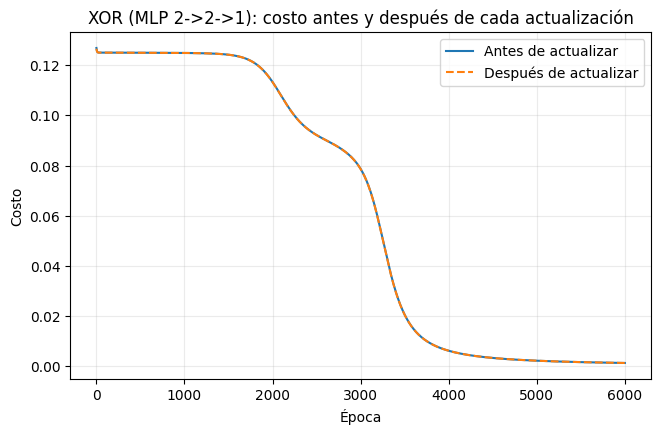

 x1   x2   salida (ŷ)   predicción   valor correcto
----------------------------------------------------
 0    0     0.0431          0               0
 0    1     0.9477          1               1
 1    0     0.9477          1               1
 1    1     0.0527          0               0

Número de aciertos: 4/4
Costo final:        0.001262


In [36]:
# 1. Graficar el historial de costo del MLP
graficar_costos_antes_despues(
    historial_mlp,
    "XOR (MLP 2->2->1): costo antes y después de cada actualización"
)

# 2. Evaluar las cuatro entradas
with torch.no_grad():
    salidas_mlp = modelo_mlp(X)
    pred_mlp = (salidas_mlp >= 0.5).int()
    aciertos_mlp = (pred_mlp == y_xor.int()).sum().item()

costo_final_mlp = historial_mlp["despues"][-1]

print(" x1   x2   salida (ŷ)   predicción   valor correcto")
print("----------------------------------------------------")
for i in range(len(X)):
    print(
        f" {int(X[i,0])}    {int(X[i,1])}     "
        f"{salidas_mlp[i].item():.4f}          "
        f"{pred_mlp[i].item()}               "
        f"{int(y_xor[i].item())}"
    )

print(f"\nNúmero de aciertos: {aciertos_mlp}/{len(X)}")
print(f"Costo final:        {costo_final_mlp:.6f}")

## Tarea 20 — Región de decisión

El color del gráfico deberá representar la salida continua:

$$
\hat y(x_1,x_2).
$$

La curva:

$$
\hat y=0.5
$$

será la frontera de decisión.

Complete la función siguiente.


<>:22: SyntaxWarning: invalid escape sequence '\h'
<>:22: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1564/237504357.py:22: SyntaxWarning: invalid escape sequence '\h'
  plt.colorbar(contorno, label="Salida continua $\hat{y}(x_1, x_2)$")


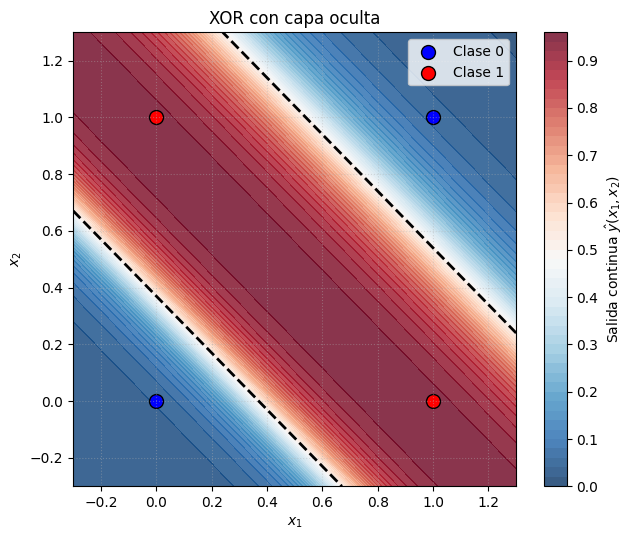

In [37]:
def graficar_region_decision(modelo, X, y, titulo):
    # 1. Crear una grilla de puntos en el plano.
    eje = torch.linspace(-0.3, 1.3, 180)
    xx, yy = torch.meshgrid(eje, eje, indexing="xy")
    puntos = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1)

    # 2. Evaluar el modelo sobre toda la grilla sin gradientes.
    with torch.no_grad():
        zz = modelo(puntos).reshape(xx.shape)

    # 3. Preparar los puntos originales en NumPy.
    xx_np = xx.numpy()
    yy_np = yy.numpy()
    zz_np = zz.numpy()
    Xn = X.numpy()
    yn = y.numpy().reshape(-1)

    plt.figure(figsize=(6.5, 5.5))

    # 4. Dibujar contourf para la salida continua y^(x1, x2).
    contorno = plt.contourf(xx_np, yy_np, zz_np, levels=50, cmap="RdBu_r", alpha=0.8)
    plt.colorbar(contorno, label="Salida continua $\hat{y}(x_1, x_2)$")

    # 5. Dibujar la curva de nivel y^ = 0.5 (frontera de decisión).
    plt.contour(xx_np, yy_np, zz_np, levels=[0.5], colors="black", linewidths=2, linestyles="--")

    # 6. Superponer las dos clases originales.
    plt.scatter(Xn[yn == 0, 0], Xn[yn == 0, 1], color="blue", edgecolor="black", s=100, label="Clase 0")
    plt.scatter(Xn[yn == 1, 0], Xn[yn == 1, 1], color="red", edgecolor="black", s=100, label="Clase 1")

    # 7. Agregar ejes, título y leyenda.
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.title(titulo)
    plt.legend(loc="upper right")
    plt.grid(True, linestyle=":", alpha=0.4)
    plt.tight_layout()
    plt.show()

# Ejecutar la visualización para el MLP entrenado
graficar_region_decision(modelo_mlp, X, y_xor, "XOR con capa oculta")

# 8. Comparación final

Complete la tabla:

| Aspecto | Perceptrón simple | Red con capa oculta |
|---|---|---|
| Entradas | 2 | 2 |
| Capa oculta | No | Sí |
| Número de parámetros |  3(2 pesos y sesgo)| 9 (6 capas oculata y 3 en salida) |
| Tipo de frontera en el plano original | lineal | no lineal |
| ¿Representa OR? | si | si |
| ¿Representa XOR? | no | si |

## Preguntas de cierre

1. ¿El descenso por gradiente consiguió disminuir el costo en el perceptrón simple aplicado a XOR?
2. ¿Por qué eso no implica necesariamente una clasificación perfecta?
3. ¿Por qué más épocas no solucionan una limitación de representación?
4. ¿Qué aporta la capa oculta?
5. ¿Qué papel cumple la no linealidad introducida por `nn.Sigmoid()`?
6. ¿Qué diferencias observa entre la frontera lineal y la región de decisión del modelo multicapa?


Preguntas de cierre

**¿El descenso por gradiente consiguió disminuir el costo en el perceptrón simple aplicado a XOR?** Sí, ligeramente al principio. Descendió desde su valor inicial aleatorio hasta estabilizarse asintóticamente en el mínimo matemático posible para una recta en este problema.

**¿Por qué eso no implica necesariamente una clasificación perfecta?** Porque minimizar la función de costo solo encuentra el mejor modelo posible dentro de la familia de funciones permitida por la arquitectura. En XOR, la recta que minimiza el error cuadrático medio colapsa todas las predicciones hacia la máxima incertidumbre ($\hat{y} \approx 0.5000$), logrando apenas $2/4$ aciertos ($50\%$), lo cual equivale a decidir al azar.   

**¿Por qué más épocas no solucionan una limitación de representación?** Porque entrenar durante más épocas únicamente ejecuta más pasos de optimización sobre los mismos parámetros, pero no cambia la estructura algebraica ni la expresividad del modelo. Una única neurona siempre estará restringida a trazar un único hiperplano lineal sin importar cuántas iteraciones se realicen.

**¿Qué aporta la capa oculta?** Aporta capacidad de representación mediante transformaciones intermedias. Cada neurona oculta actúa como un detector de características lineal distinto; al combinar ambas en la capa de salida, la red proyecta los datos originales $(x_1, x_2)$ a un nuevo espacio latente $(h_1, h_2)$ donde las clases de XOR sí son linealmente separables.


**¿Qué papel cumple la no linealidad introducida por nn.Sigmoid()?** Es indispensable para que la profundidad de la red tenga efecto. Si las capas ocultas fueran puramente lineales (sin función de activación no lineal), la composición de dos transformaciones afines seguiría siendo una única transformación afín ($W_2(W_1x + b_1) + b_2 = W'x + b'$), colapsando matemáticamente de nuevo a un perceptrón simple incapaz de resolver XOR.

**¿Qué diferencias observa entre la frontera lineal y la región de decisión del modelo multicapa?** Mientras que el perceptrón simple solo puede trazar una línea recta que inevitablemente deja puntos de distintas clases mezclados, el modelo multicapa genera dos fronteras curvas/diagonales ($\hat{y} = 0.5$) que aíslan una franja central para la Clase 1 ((0,1) y (1,0)) y dejan las dos esquinas opuestas en la región de la Clase 0 ((0,0) y (1,1)).